## Learning goals

By the end of this lab, you should be able to:

- load and inspect a CSV file as a Pandas DataFrame;
- distinguish Pandas data types from quantitative and categorical feature types;
- check for missing values;
- create and label a histogram and a bar chart;
- describe a distribution by its typical values, range, and skew;
- use `.describe()` to check estimates made from a histogram;
- explain how histogram bins and axis scales affect a figure; and
- identify conclusions that can and cannot be supported by a sample; and
- find a documented dataset, audit every feature, and interpret its quantitative and categorical distributions.


## Using AI tools responsibly

You may use an AI tool to ask questions, debug code, or receive feedback. You are still responsible for understanding every part of your submission and checking suggestions against your notebook's output. At the end of the lab, disclose whether you used an AI tool and how you evaluated its advice.


## Dataset

The [U.S. Bureau of Transportation Statistics (BTS) Reporting Carrier On-Time Performance data](https://www.transtats.bts.gov/DL_SelectFields.aspx?QO_fu146_anzr=b0-gvzr&gnoyr_VQ=FGJ) contains 611,735 reported domestic flight records for May 2026. Completed, non-diverted flights with recorded values for all five selected features were eligible for this lab. Canceled flights, diverted flights, and records missing any selected feature were excluded before the sample was drawn.

The dataset is a reproducible random sample of 5,000 eligible flights. Each observation represents one completed, non-diverted domestic flight in that sample. Because incomplete records were removed before sampling, finding no missing values in the dataset does not mean that the original BTS data had no missing values. Conclusions from this sample describe the eligible flights and should not automatically be generalized to canceled or diverted flights.

| Feature | Description |
| --- | --- |
| `airline` | Airline that reported the flight |
| `origin_city` | Departure city |
| `destination_city` | Arrival city |
| `distance_miles` | Nonstop flight distance in miles |
| `arrival_delay_minutes` | Minutes between scheduled and actual arrival; negative values mean the flight arrived early |


## Load and preview the data

Import Pandas using the conventional alias `pd`. Read `data/bts_flights_may_2026_sample.csv` into a DataFrame named `flights`.


In [18]:
import pandas as pd
flights = pd.read_csv("data/bts_flights_may_2026_sample.csv")

Display the first five rows of the DataFrame.


In [19]:
flights.head()


,airline,origin_city,destination_city,distance_miles,arrival_delay_minutes
0,Alaska Airlines,"Anchorage, AK","Chicago, IL",2846,65
1,Alaska Airlines,"Anchorage, AK","Cordova, AK",160,-1
2,Alaska Airlines,"Anchorage, AK","Fairbanks, AK",261,-18
3,Alaska Airlines,"Anchorage, AK","Juneau, AK",571,-21
4,Alaska Airlines,"Anchorage, AK","Juneau, AK",571,-14


Display the last five rows of the DataFrame.


In [20]:
flights.tail()


,airline,origin_city,destination_city,distance_miles,arrival_delay_minutes
4995,United Airlines,"West Palm Beach/Palm Beach, FL","Chicago, IL",1144,0
4996,United Airlines,"West Palm Beach/Palm Beach, FL","Houston, TX",956,-22
4997,United Airlines,"West Palm Beach/Palm Beach, FL","Houston, TX",956,-29
4998,United Airlines,"West Palm Beach/Palm Beach, FL","Newark, NJ",1024,-26
4999,United Airlines,"West Palm Beach/Palm Beach, FL","Newark, NJ",1024,7


## Inspect the DataFrame

Display a summary of the DataFrame that includes the feature names, the number of non-missing values, and the Pandas data types.


In [21]:
flights.info()


<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   airline                5000 non-null   str  
 1   origin_city            5000 non-null   str  
 2   destination_city       5000 non-null   str  
 3   distance_miles         5000 non-null   int64
 4   arrival_delay_minutes  5000 non-null   int64
dtypes: int64(2), str(3)
memory usage: 399.5 KB


**How many observations are in the DataFrame?**

Your answer: There are 5000 observations in the DataFrame.


Count the missing values in every feature.


In [22]:
flights.isnull().sum()


airline                  0
origin_city              0
destination_city         0
distance_miles           0
arrival_delay_minutes    0
dtype: int64

## Classify the features

A **quantitative feature** records an amount or measurement for which arithmetic is meaningful. A **categorical feature** assigns observations to groups or labels.


**Complete the table with the Pandas data type, feature type, and number of missing values for each feature. Use `.info()` and `.isnull().sum()`; enter 0 when no values are missing.**

| Feature | Pandas data type | Feature type | Number of missing values |
| --- | --- | --- | ---: |
| `airline` | str | categorical | 0 |
| `origin_city` | str | categorical | 0 |
| `destination_city` | str | categorical | 0 |
| `distance_miles` | int64 | quantative | 0 |
| `arrival_delay_minutes` | int64 | quantative | 0 |


## Which destination city is most common in the sample?

Calculate and display the frequency of each destination city. Save the result as `destination_counts`.


In [23]:
destination_counts = flights["destination_city"].value_counts()
destination_counts


destination_city
Chicago, IL                      296
Atlanta, GA                      222
Dallas/Fort Worth, TX            210
Denver, CO                       209
Washington, DC                   165
                                ... 
Watertown, SD                      1
Cedar City, UT                     1
Sun Valley/Hailey/Ketchum, ID      1
Carlsbad, CA                       1
Redding, CA                        1
Name: count, Length: 238, dtype: int64

Import `matplotlib.pyplot` using the conventional alias `plt`. Use `.head(10)` on `destination_counts` to select the ten most frequent destination cities, then create a bar chart. Give the figure a descriptive title and label both axes.


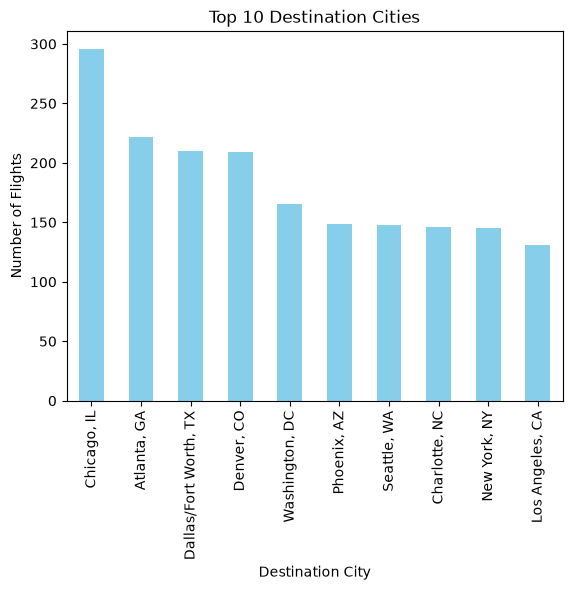

In [24]:
import matplotlib.pyplot as plt

destination_counts.head(10).plot(kind="bar", color="skyblue")
plt.xlabel("Destination City")
plt.ylabel("Number of Flights")
plt.title("Top 10 Destination Cities")
plt.show()


**Which destination city is most common in the sample?**

Your answer: Chicago, IL is the most frequent destination city in the sample with 296 flights.


## What was the distribution of arrival delays?

Negative values represent early arrivals, zero represents an on-time arrival, and positive values represent late arrivals.

Create a histogram of `arrival_delay_minutes` using the default number of bins. Give the figure a descriptive title and label both axes.


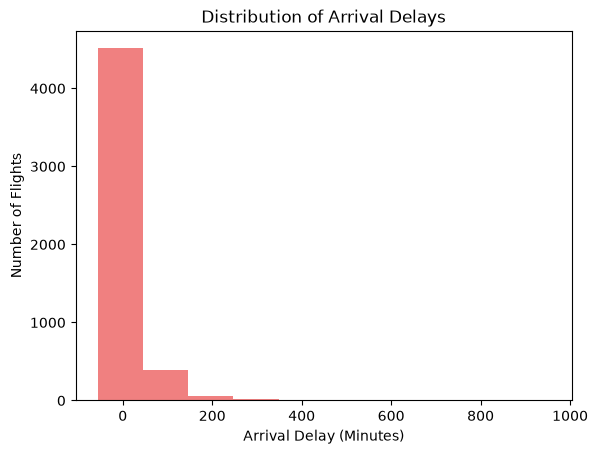

In [25]:
flights["arrival_delay_minutes"].plot(kind="hist", color="lightcoral")
plt.xlabel("Arrival Delay (Minutes)")
plt.ylabel("Number of Flights")
plt.title("Distribution of Arrival Delays")
plt.show()


**Approximately what arrival-delay value appears most common?**

Your answer: With the distribution peak being near 0 this lets us know the majority of flights arrive on time or could even be early.


**What is the approximate range from the smallest to the largest arrival-delay value?**

Your answer:
The approximate range spans roughly 1,000 minutes, we know it could go a little below zero but will max out near 1,000 minutes.

**Does the arrival-delay distribution appear symmetric or skewed?**

Your answer:
 The arrival-delay distribution appears heavily right skewed, with the majority of flights being concentrated near 0, a long sparse tail extending to the right letting us know there are a small number of flights that contain severe delays.


Display a numerical summary of `arrival_delay_minutes`.


In [26]:
flights["arrival_delay_minutes"].describe()


count    5000.000000
mean        6.098800
std        48.335493
min       -55.000000
25%       -16.000000
50%        -6.000000
75%        10.000000
max       953.000000
Name: arrival_delay_minutes, dtype: float64

Calculate and display the exact mode of `arrival_delay_minutes` using `.mode()`.


In [27]:
print("Arrival Delay:", flights["arrival_delay_minutes"].mode().tolist())


Arrival Delay: [-8]


**How closely did the calculated mode match the most common value you estimated from the histogram?**

Your answer: The calculated mode of -8 closely matches the estimation of 0, both numbers fall in center of the same bin containg the majority of flights.


**How closely did the minimum and maximum from `.describe()` match the range you estimated from the histogram?**

Your answer: With a minimun of -55 and a maximum of 953 this confirms my estimation of near 0 - 1,000 shown on the histogram.


**Is the mean greater than, less than, or approximately equal to the median?**

Your answer: The mean (6.10 mins) is greater than the median (-6 minutes).


**How is the relationship between the mean and median connected to the histogram's shape?**

Your answer: The difference between the mean and median happens because the graph is skewed to the right, while the median is in the negative which can be seen in the graph, the extremely delayed flights are outliers pulling the mean to the positive numbers which creates the long tail.


## Applying the principles: histogram bins

Re-create the arrival-delay histogram using exactly 5 bins.


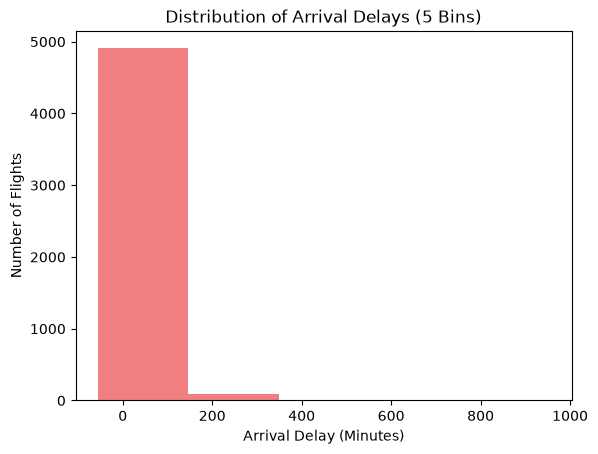

In [28]:
flights["arrival_delay_minutes"].plot(kind="hist", color="lightcoral", bins=5)
plt.xlabel("Arrival Delay (Minutes)")
plt.ylabel("Number of Flights")
plt.title("Distribution of Arrival Delays (5 Bins)")
plt.show()


Re-create the arrival-delay histogram using exactly 25 bins.


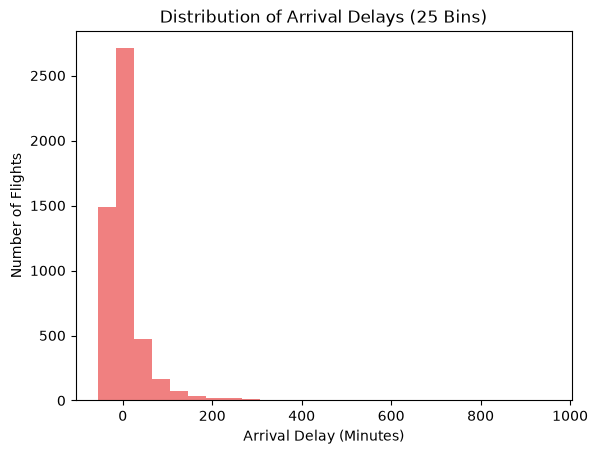

In [29]:
flights["arrival_delay_minutes"].plot(kind="hist", color="lightcoral", bins=25)
plt.xlabel("Arrival Delay (Minutes)")
plt.ylabel("Number of Flights")
plt.title("Distribution of Arrival Delays (25 Bins)")
plt.show()


**What changed when the number of bins was reduced to 5?**

Your answer: Nearly all the flights got compressed to one visual hiding any details on many flights.


**What changed when the number of bins was increased to 25?**

Your answer: It seperates more of the flights into seperate bars so we can see more flights that are early, on time and only slightly late.


**Which bin setting communicates the distribution most clearly?**

Your answer: The 25 bin view allows us to view the data more clearly allowing us to see the structure and skewness, whereas the 5 bin is less helpful because it generalizes the data too much.


## Applying the principles: a misleading vertical axis

Run both cells below and compare the figures.


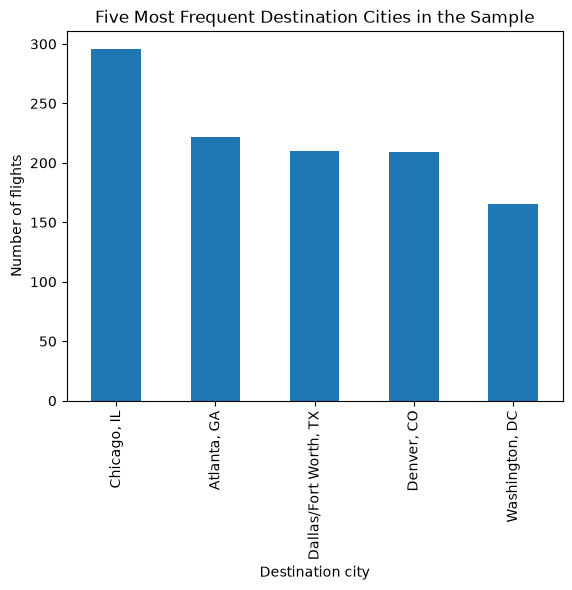

In [30]:
top_destinations = destination_counts.head(5)
top_destinations.plot(kind="bar")
plt.title("Five Most Frequent Destination Cities in the Sample")
plt.xlabel("Destination city")
plt.ylabel("Number of flights")
plt.show()


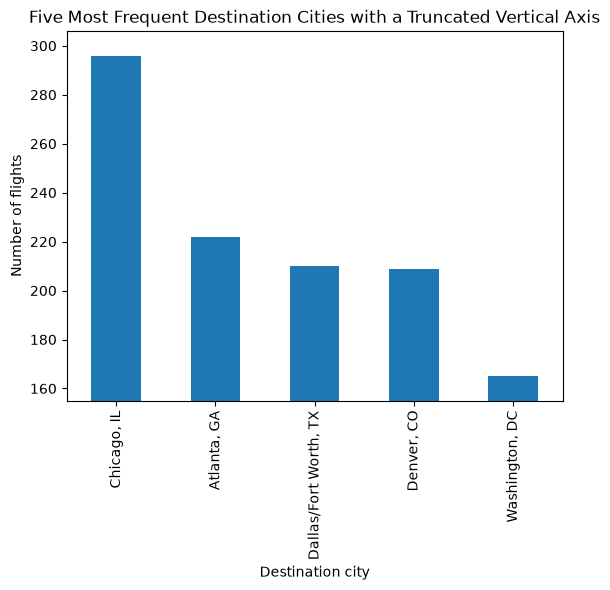

In [31]:
top_destinations.plot(kind="bar")
plt.ylim(top_destinations.min() - 10, top_destinations.max() + 10)
plt.title("Five Most Frequent Destination Cities with a Truncated Vertical Axis")
plt.xlabel("Destination city")
plt.ylabel("Number of flights")
plt.show()


**How does the truncated axis change the apparent differences among the destination cities?**

Your answer: The truncated axis misleads the information having you believe Chicago is x times the amount of Washington whereas the reality is Chicago isn't even twice the amount of Washington.


**Which chart communicates the counts more honestly?**

Your answer:The first chart without the truncated axis is the more honest chart because the chart visually matches the information more accuratly at first sight. The reader will be able to see accurate proportions/comparisons from the beginning.


## Is this sample representative?

Review the dataset description at the top of the lab before answering these questions.


**What time period is represented by the source data?**

Your answer: The source data if of May 2026.


**Which flights were eligible to be included in the sample?**

Your answer: Flights that were completed, non diverted and had values that met all five selected features were eligible to be included in the sample.


**Which flights and records were excluded before the sample was selected?**

Your answer: Flights that were cancelled, diverted, or had any records missing for the selected features were excluded in this sample.


**Does finding no missing values in the sample prove that the original BTS data had no missing values?**

Your answer: No, finding no missing values doesnt mean the BTS data didn't contain any, but it does mean the exclusions worked for the data needed in this sample to ensure we're only working with complete data sets.


**Why should conclusions from this sample not automatically be generalized to canceled or diverted flights?**

Your answer: These conclusions cannot be applied to diverted or cancelled flights because the sample set didn't contain any of those flights information to begin with.


## Choosing a chart

Choose a histogram, bar chart, or pie chart for each question. Use the question and number of categories to justify your choice.


**Which chart would you use to show the frequency of each airline?**

Your answer: Because frequency accross airlines is comparing categories the best chart to use would be a bar chart. This way you could see the frequency of each airline individually.


**Which chart would you use to show what proportion of sampled flights were early, on time, and delayed? Use arrival delays below 0, equal to 0, and above 0 minutes, respectively.**

Your answer: Because we're needing to see the data broken into three categories, using a pie chart would be best so we could visually see the percentage of each category and how they compare to one another.


**Which chart would you use to show the distribution of flight distances?**

Your answer: Because we're looking at distribution of flight distances and this is considered a continuous quantative measurement a histogram would be the best chart to to see the spread of distance, shape, and center.


## Explore a dataset of your own

Apply the same inspection and visualization process to a different dataset that interests you.

### 1. Find and describe your dataset

Start with [Kaggle Datasets](https://www.kaggle.com/datasets), the [UCI Machine Learning Repository](https://archive.ics.uci.edu/), or [Data.gov](https://catalog.data.gov/). You can also search a city or state open-data portal. Search for a topic you enjoy, such as sports, music, animals, transportation, or the environment.

Choose a manageable CSV file with a data dictionary (or equivalent feature documentation), at least one quantitative feature, and at least one categorical feature with a manageable number of categories. Use a different dataset from the flights and penguins already used in class. Save the file in this notebook's `data` folder.

Read the data dictionary before choosing your features. In a short paragraph, describe the dataset's subject, what one row represents, and its time period and geographic coverage if documented. Include its title, publisher or creator, a direct link to the dataset, and a link to the data dictionary. State when information is not documented instead of guessing.


**Dataset description and source links:**

Your answer: This dataset contains transaction and user engagement records from a pet food subscription e-commerce platform. Each row represents an individual customer order profile, tracking specific pet traits (like life stage, breed size, and health conditions), detailed caloric allocations (kibble vs. wet food), and website activity (browsing duration and session counts). The exact geographic market and collection dates are not documented by the author.

Dataset Title: Pet Food Customer Orders Online
Publisher/Creator: Man of King (nolenja) / Jahangir Raina 
Direct Dataset Link: [Kaggle Dataset Source](https://www.kaggle.com/datasets/jahangirraina/pet-food-customer-orders-online)
Data Dictionary Link: [Kaggle Code Notebook Documentation](https://www.kaggle.com/code/nolenja/pet-food-customer-order)


### 2. Load the data and describe every feature

Load your CSV into a new DataFrame with a descriptive name ending in `_df`, such as `movies_df`, `weather_df`, or `animals_df`. Choose a name that describes your dataset and use it consistently throughout your analysis. Display its first five rows, shape, `.info()`, and `.isnull().sum()` to inspect its features, storage types, and missing values. Use a relative path so your notebook can run on another computer.


In [32]:
pet_orders_df = pd.read_csv("data/pet_food_customer_orders.csv")

print("--- First 5 Rows ---")
display(pet_orders_df.head())

print("Shape of the DataFrame:", pet_orders_df.shape)

print("\n--- DataFrame Info ---")
pet_orders_df.info()

print("\n--- Missing Values Count ---")
print(pet_orders_df.isnull().sum())

--- First 5 Rows ---


,customer_id,pet_id,pet_order_number,wet_food_order_number,orders_since_first_wet_trays_order,pet_has_active_subscription,pet_food_tier,pet_signup_datetime,pet_allergen_list,pet_fav_flavour_list,...,dental_treat_packs,wet_food_textures_in_order,total_web_sessions,total_web_sessions_since_last_order,total_minutes_on_website,total_minutes_on_website_since_last_order,total_wet_food_updates,total_wet_food_updates_since_last_order,last_customer_support_ticket_date,customer_support_ticket_category
0,10574848487411271014,4466839344031767293,2,1.0,1.0,True,superpremium,1970-01-01 00:00:01.552397819,NaN,Chicken,...,0,gravy jelly pate,6,4,101,32,0,0,2019-03-16 09:10:12+00:00,proactive
1,10574848487411271014,4466839344031767293,1,NaN,NaN,True,superpremium,1970-01-01 00:00:01.552397819,NaN,Chicken,...,0,NaN,2,1,69,3,0,0,2019-03-16 09:10:12+00:00,proactive
2,10574848487411271014,4466839344031767293,8,7.0,7.0,True,superpremium,1970-01-01 00:00:01.552397819,NaN,Chicken,...,0,gravy jelly pate,18,0,184,0,0,0,2019-10-26 06:10:13+00:00,account
3,10574848487411271014,4466839344031767293,4,3.0,3.0,True,superpremium,1970-01-01 00:00:01.552397819,NaN,Chicken,...,0,gravy jelly pate,13,6,130,15,0,0,2019-04-23 06:28:12+00:00,account
4,10574848487411271014,4466839344031767293,9,8.0,8.0,True,superpremium,1970-01-01 00:00:01.552397819,NaN,Chicken,...,0,gravy jelly pate,19,1,184,0,0,0,2019-10-26 06:10:13+00:00,account


Shape of the DataFrame: (49042, 36)

--- DataFrame Info ---
<class 'pandas.DataFrame'>
RangeIndex: 49042 entries, 0 to 49041
Data columns (total 36 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   customer_id                                49042 non-null  uint64 
 1   pet_id                                     49042 non-null  uint64 
 2   pet_order_number                           49042 non-null  int64  
 3   wet_food_order_number                      12788 non-null  float64
 4   orders_since_first_wet_trays_order         14372 non-null  float64
 5   pet_has_active_subscription                49042 non-null  bool   
 6   pet_food_tier                              49042 non-null  str    
 7   pet_signup_datetime                        49042 non-null  str    
 8   pet_allergen_list                          10758 non-null  str    
 9   pet_fav_flavour_list                       21

Complete the table below with **one row for every feature** in your dataset. Add as many rows as needed. Use the data dictionary to summarize what each feature means, including units or category-code meanings where relevant.

- **Data type:** quantitative or categorical; identify identifiers and date/time features explicitly when appropriate. A numeric identifier is not a quantitative measurement.
- **Data storage type:** the actual Pandas dtype shown by `.info()` or `.dtypes`, such as `int64`, `float64`, `object`, `str`, or `datetime64[ns]`.
- **Missing values:** the number reported for that feature, including 0 when there are none. Count missing values before removing records. If the dictionary defines special missing codes, such as -999 or "Unknown", explain how you handle those codes and make sure the counts reflect that decision.


| Feature | Description from the data dictionary (including units/codes) | Data type | Data storage type | Number of missing values |
| --- | --- | --- | --- | ---: |
| `customer_id` | Unique identification tracker number for the pet owner | Categorical | object | 0 |
| `pet_id` | Unique identification tracker number for the pet profile | Categorical | object | 0 |
| `pet_order_number` | Cumulative order counter for a specific pet profile	| Quantitative	| int64 | 0 |	
| `wet_food_order_number` | Cumulative counter of orders containing wet food items | Quantitative | float64 | 36254 |
| `orders_since_first_wet_trays_order` | Number of orders placed after the first wet food tray purchase | Quantitative | float64 | 34670 |
| `pet_has_active_subscription` | Indicator if the pet profile has an active subscription (True/False) | Categorical | bool | 0 |
| `pet_food_tier` | Tier classification level of the custom recipe plan | Categorical | str | 0 |
| `pet_signup_datetime` | The calendar date and timestamp of the pet's signup profile creation | Categorical | str | 0 |
| `pet_allergen_list` | String list recording flagged food allergies or restrictions | Categorical | str | 38284 |
| `pet_fav_flavour_list` | List recording the preferred flavour profile settings for the pet | Categorical | str | 28020 |
| `pet_health_issue_list` | List of documented health considerations or medical priorities | Categorical | str | 25326 |
| `neutered` | Indicator if the pet has been neutered or spayed (True/False) | Categorical | bool | 0 |
| `gender` | Biological sex designation of the pet (Male/Female) | Categorical | str | 0 |
| `pet_breed_size` | Size category partition for the pet's breed size profile | Categorical | str | 0 |
| `signup_promo` | Text descriptor or code of the sign-up discount promotional offer used | Categorical | str | 0 |
| `ate_wet_food_pre_tails` | Indicator if the pet ate wet food before joining (True/False) | Categorical | bool | 0 |
| `dry_food_brand_pre_tails` | Brand of dry pet food used before joining the subscription | Categorical | str | 6372 |
| `pet_life_stage_at_order` | Life stage of the pet at the time of the order transaction | Categorical | str | 0 |
| `order_payment_date` | The specific calendar date the order transaction payment was finalized | Categorical | str | 0 |
| `kibble_kcal`| Calculated daily energy requirement allocated from dry kibble (kilocalories) | Quantitative | float64 | 0 |
| `wet_kcal` | Calculated daily energy requirement allocated from wet trays (kilocalories) | Quantitative | float64 | 0 |
| `total_order_kcal` | Total caloric value packed into the specific recipe package order | Quantitative | float64 | 0 |
| `wet_trays` | Total numeric count of wet food trays included inside the shipment order | Quantitative | int64 | 0 |
| `wet_food_discount_percent` | Percentage-based promotional price markdown applied to the wet trays | Quantitative | float64 | 36254 |
| `wet_tray_size` | Volumetric size or weight profile description for wet food trays | Categorical | str | 36254 |
| `premium_treat_packs` | Dispatched quantity count of premium treat packages bundled in the order | Quantitative | int64 | 0 |
| `dental_treat_packs` | Dispatched quantity count of dental treat packages bundled in the order | Quantitative | int64 | 0 |
| `wet_food_textures_in_order `| Structural list of specific meat texture categories selected for the order | Categorical | str | 36254 |
| `total_web_sessions` | Lifetime summary counter tracking total customer website log-in sessions | Quantitative | int64 | 0 |
| `total_web_sessions_since_last_order` | Website session interaction counter logged strictly between active orders | Quantitative | int64 | 0 |
| `total_minutes_on_website` | Lifetime sum of browsing duration tracked on the online storefront (minutes) | Quantitative | int64 | 0 |
| `total_minutes_on_website_since_last_order` | Browsing duration tracked on the online storefront between active orders (minutes) | Quantitative | int64 | 0 |
| `total_wet_food_updates` | Lifetime index tracking modifications made to wet food settings profile | Quantitative | int64 | 0 |
| `total_wet_food_updates_since_last_order` | Modifications made to wet food profile metrics since the previous order window | Quantitative | int64 | 0 |
| `last_customer_support_ticket_date` | Calendar date recording the latest customer service ticket creation timeline | Categorical | str | 38762 |
| `customer_support_ticket_category` | Operational category label applied to clarify the customer support ticket topic | Categorical | str | 38801 |

**Missing-value codes or other data preparation, if applicable:**

Your answer:

Structural Missingness: Variables tracking wet-food metrics (such as wet_food_order_number and wet_tray_size) share 36,254 missing rows. This is normal behavior showing that these accounts have a dry-food-only subscription.

Optional Profile Fields: Features like pet_allergen_list and pet_health_issue_list have thousands of missing values because listing medical or allergy details is optional.

Data Preparation: No rows need to be deleted. To clean this up for analysis, these empty values will simply be filled with a placeholder string like "None" or "No Restrictions".


### 3. Visualize one quantitative feature

Choose one quantitative measurement and create an appropriate visualization of its distribution, such as a histogram. Include a descriptive title, a horizontal-axis label naming the feature and its units, and a vertical-axis label explaining what the heights represent. Explain any excluded missing values or other filtering. Do not use an ID number as your quantitative feature.


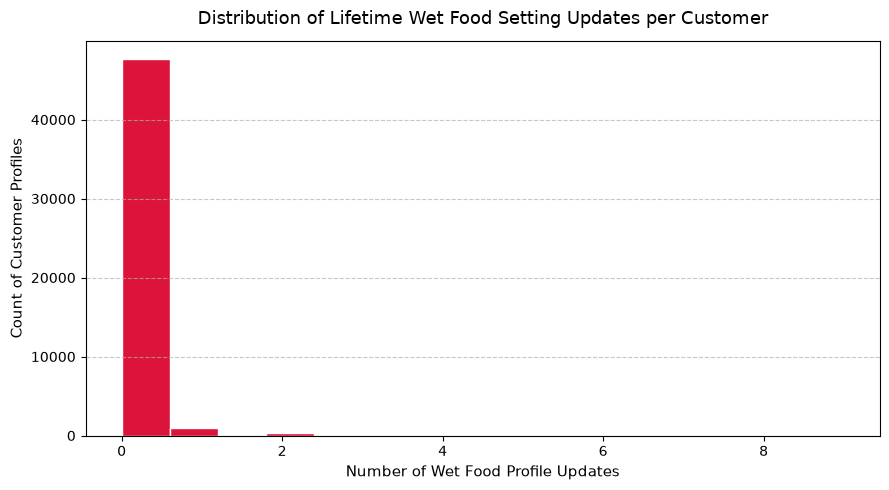

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

pet_orders_df["total_wet_food_updates"].hist(bins=15, color="crimson", edgecolor="white", grid=False)

plt.title("Distribution of Lifetime Wet Food Setting Updates per Customer", fontsize=13, pad=12)
plt.xlabel("Number of Wet Food Profile Updates", fontsize=11)
plt.ylabel("Count of Customer Profiles", fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

**Which feature did you choose, and why is this chart appropriate?**

Your answer:
I chose the total_wet_food_updates feature. A histogram is the right choice because the number of account changes is a numeric measurement. Grouping these counts into bins allows us to easily see the overall shape and spread of customer behavior. No values were left out because this column has 0 missing entries.

**In at least one complete sentence, describe what the figure tells you about this feature.** Refer to a visible pattern such as typical values, range, shape, or unusual observations, using values and units where possible. Describe the observations in your dataset without assuming they represent a larger population.

Your interpretation:
The graph shows a very strong right-hand skew, with a massive peak right at zero. This tells us that the majority of users never change their wet food settings after signing up. The long, flat tail extending to the right shows a small group of customers who do constantly log in to edit their settings.



### 4. Visualize one categorical feature

Choose a categorical feature and create an appropriate visualization of its distribution. A bar chart of category counts is a good choice; use `.value_counts()` to obtain numeric bar heights from text labels. Include a descriptive title and labels identifying the categories and counts or percentages on the axes. If you choose a pie chart for a small number of categories, label the slices and their shares instead of axes. Explain any excluded missing values or categories, and identify the denominator if you use percentages.


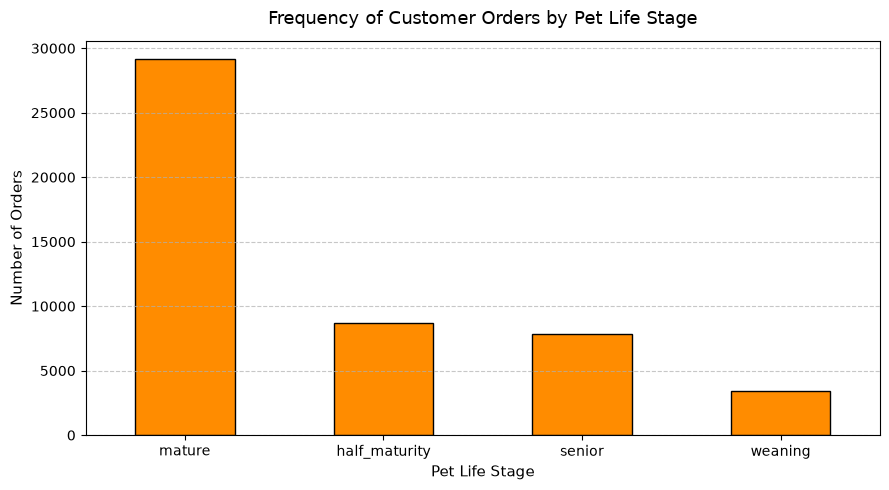

In [34]:
# Create and label your categorical-feature visualization here.
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

lifestage_counts = pet_orders_df["pet_life_stage_at_order"].value_counts()

lifestage_counts.plot(kind="bar", color="darkorange", edgecolor="black")

plt.title("Frequency of Customer Orders by Pet Life Stage", fontsize=13, pad=12)
plt.xlabel("Pet Life Stage", fontsize=11)
plt.ylabel("Number of Orders", fontsize=11)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

**Which feature did you choose, and why is this chart appropriate?**

Your answer:
 I chose the pet_life_stage_at_order feature. A bar chart is the right choice because a pet's life stage is a categorical variable with just a few text options. Using .value_counts() lets us easily graph and compare the exact number of orders for each group. No data was left out because this feature has 0 missing rows.


**In at least one complete sentence, describe what the figure tells you about this feature.** Identify a meaningful pattern, such as the most or least common category or a difference in counts or shares. Support the interpretation with evidence visible in your figure.

Your interpretation:
The bar chart shows a clear difference among the groups, with adult pets making up the highest number of orders. There is a large gap between this leading group and the puppy or senior stages, which appear much less frequently. This pattern demonstrates that the platform's main users have mature pets, while growing and older animals make up smaller parts of the dataset.



## Reflect on AI assistance

Complete one of the following statements.

**If you used an AI tool:**

- Tool used:
- What I asked it to help with:
- One suggestion I checked against my code, chart, or output:
- What I accepted, modified, or rejected—and why:

**If you did not use an AI tool:**

- I did not use an AI tool for this assignment.
- One resource or troubleshooting strategy I used instead was:


Your response:
Your answer:

Yes, I used an AI tool to help refine my raw data observations and improve the sentence structure of my final interpretations. While I had the correct calculations, my original drafts lacked clean data vocabulary.

• Example 1 (Quantitative Interpretation): When looking at the total_wet_food_updates histogram, my first draft simply stated that most customers had zero updates and a few had a lot. The AI tool reworded this into a polished description, introducing proper statistical terms like "strong right-skewed distribution" and explaining clearly that the long, flat tail represents a unique subset of highly active power users.

• Example 2 (Missing Data Section): My initial explanation for why the dataset had so many empty rows was disorganized. The AI helped me restructure the thought into a clear summary, using the term "structural missingness" to explain that empty cell blocks for pet allergies were simply skipped optional traits rather than broken system errors.



## Submission checklist

- All code cells run from top to bottom without errors.
- The destination-city bar chart has a descriptive title and labeled axes.
- The default, 5-bin, and 25-bin arrival-delay histograms are included and labeled.
- Both vertical-axis demonstrations are included.
- Every question has one response in its own answer cell.
- The sample questions are answered using the dataset documentation.
- The chosen dataset and its data dictionary are linked and described.
- The feature table includes a description, data type, storage type, and missing-value count for every feature.
- One quantitative and one categorical feature have appropriate labeled visualizations and at least one sentence of interpretation each.
- The chosen CSV is included in the `data` folder with the submitted notebook, and relative paths work.
- The AI-use reflection is complete and honest.
